In [ ]:
import numpy as np


### Gradient Descent
$$
h(x) = w_1x + w_2
$$
 
$$
J(w_1,w_2) = \frac{1}{2n}\sum_{i=1}^{n}\left(h(x_i)-y_i\right)^2
$$
 
$$
\begin{aligned}
w_1 &:= w_1 - \alpha \frac{\partial J}{\partial w_1}
     = w_1 - \frac{\alpha}{n}\sum_{i=1}^{n}\left(h(x_i)-y_i\right)x_i \\[6pt]
w_2 &:= w_2 - \alpha \frac{\partial J}{\partial w_2}
     = w_2 - \frac{\alpha}{n}\sum_{i=1}^{n}\left(h(x_i)-y_i\right)
\end{aligned}
$$
 
 

In [21]:
x = np.array([1, 2, 3, 4, 5])
price_values = np.array([2, 4, 6, 8, 10])

def find_w1_w2(x, y, alpha, max_iter=10000, tol=1e-8):
    w1 = 0.0
    w2 = 0.0
    previous_loss = np.sum((y - (w1 * x + w2)) ** 2)

    for iteration in range(1, max_iter + 1):
        y_pred = w1 * x + w2

        dw1 = -2 * np.sum(x * (y - y_pred))
        dw2 = -2 * np.sum(y - y_pred)

        w1 -= alpha * dw1
        w2 -= alpha * dw2

        new_predictions = w1 * x + w2
        loss = np.sum((y - new_predictions) ** 2)

        if not np.isfinite(loss):
            raise ValueError("Loss is not finite. Try a smaller learning rate.")

        improvement = previous_loss - loss

        if 0 <= improvement < tol:
            print(f"Stopped early at iteration {iteration}. Loss: {loss:.10f}")
            break

        previous_loss = loss
    else:
        print(f"Reached the maximum of {max_iter} iterations.")

    return w1, w2

w1, w2 = find_w1_w2(x, price_values, alpha=0.01)

print("w1:", w1)
print("w2:", w2)

Stopped early at iteration 400. Loss: 0.0000002873
w1: 1.9998443802099921
w2: 0.0005618368198197761


In [22]:
# 1. Implement gradient decent with 2 parameters.
# 2. implement early stopping.
# 3. implement gradient decent with many parameters and test with diamonds dataset.


In [26]:
import matplotlib.pyplot as plt
%matplotlib ipympl
import numpy as np

iteration 1: w1 = -1.9706321880254578, w2 = -0.26768781393938507, J = 91.67884822118465
iteration 11: w1 = 1.5443612939699949, w2 = 0.6369559304361346, J = 0.628891864537317
iteration 21: w1 = 1.8301900154820936, w2 = 0.6627913778791754, J = 0.0759610123088654
iteration 31: w1 = 1.8619742076981272, w2 = 0.6303413661850246, J = 0.07157821955382546
iteration 41: w1 = 1.8718301149971945, w2 = 0.6011619509447831, J = 0.07093219190104748
iteration 51: w1 = 1.8783075637102693, w2 = 0.578274541396692, J = 0.07055764526537653
iteration 61: w1 = 1.8832286398729479, w2 = 0.5605466608712396, J = 0.07033363137225424
iteration 71: w1 = 1.8870281055430262, w2 = 0.546832400467543, J = 0.07019960725059686
iteration 81: w1 = 1.8899664145520052, w2 = 0.5362244073063847, J = 0.07011942238749688
iteration 91: w1 = 1.8922391252666722, w2 = 0.5280192187589435, J = 0.07007144884063439


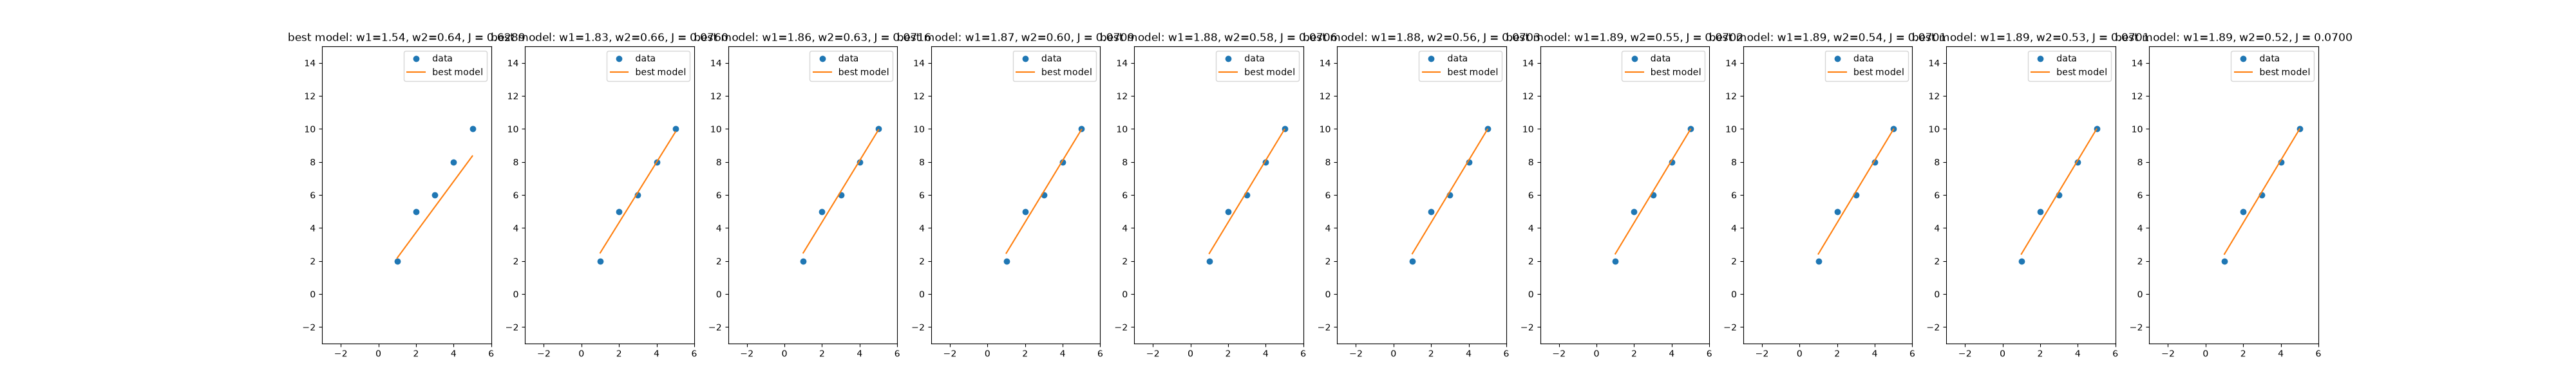

In [27]:
CaratValues = np.array([1, 2, 3, 4, 5])
price_values = np.array([2, 5, 6, 8, 10])
 
def h(X, w1, w2):
    return w1 * X + w2
 
def J(X, y, w1, w2):
    n = len(y)
    return np.sum((h(X, w1, w2) - y) ** 2) / (2 * n)
 
def find_w1_w2(X, y, alpha, max_iter=10, min_delta=1e-8, patience=5):
    w1, w2 = np.random.randn(2)
    n = len(y)
    
    best_w1, best_w2 = w1, w2
    best_loss = J(X, y, w1, w2)
    previous_loss = best_loss
    no_improvement_count = 0
    
    fig, ax = plt.subplots(1, 10, figsize=(40, 6))
    for i in range(max_iter):
        if i % 10 == 0:
            ax[i // 10].plot(X, y, marker='o', ls='', lw=4, label='data')
            ax[i // 10].plot(X, h(X, w1, w2), label='model')
            ax[i // 10].set_title(f"i{i+1} w1 = {w1:.2f}, w2 = {w2:.2f}, J = {J(X, y, w1, w2):.2f}")
            ax[i // 10].set_xlim(-3, 6)
            ax[i // 10].set_ylim(-3, 15)
            ax[i // 10].legend()
            print(f"iteration {i+1}: w1 = {w1}, w2 = {w2}, J = {J(X, y, w1, w2)}")
        
        predictions = h(X, w1, w2)
        w1_tmp = w1 - alpha * np.sum((predictions - y) * X) / n
        w2_tmp = w2 - alpha * np.sum((predictions - y)) / n
        w1, w2 = w1_tmp, w2_tmp
        
        current_loss = J(X, y, w1, w2)
        
        if current_loss < best_loss:
            best_loss = current_loss
            best_w1, best_w2 = w1, w2
        
        improvement = previous_loss - current_loss
        if improvement > min_delta:
            no_improvement_count = 0
        else:
            no_improvement_count += 1
        
        previous_loss = current_loss
        
        if no_improvement_count >= patience:
            print(f"No significant improvement for {patience} consecutive iterations. Stopping early.")
            break
        
        w1, w2 = best_w1, best_w2
        
        final_ax = ax[min(i // 10, len(ax) - 1)]
        final_ax.clear()
        final_ax.plot(X, y, marker='o', ls='', lw=4, label='data')
        final_ax.plot(X, h(X, w1, w2), label= 'best model')
        final_ax.set_title(f"best model: w1={w1:.2f}, w2={w2:.2f}, J = {best_loss:.4f}")
        final_ax.set_xlim(-3, 6)
        final_ax.set_ylim(-3, 15)
        final_ax.legend()
        

        previous_loss = current_loss
    plt.savefig('gradient_descent.png')
    plt.show()
    return w1, w2
 
w1, w2 = find_w1_w2(CaratValues, price_values, alpha=0.15, max_iter=100)

iteration 1: w1 = 0.5547240107344995, w2 = 0.3696184418164689, J = 10.558418394477656
iteration 11: w1 = 1.7519773092133388, w2 = 0.6463690122649015, J = 0.13622308217847112
iteration 21: w1 = 1.8549507663340616, w2 = 0.632450078730941, J = 0.07203307203683565
iteration 31: w1 = 1.8705581136382718, w2 = 0.6039454276092764, J = 0.0709888132569101
iteration 41: w1 = 1.877647401188491, w2 = 0.5805171974882362, J = 0.07059021641199058
iteration 51: w1 = 1.882743198035942, w2 = 0.5622883094668941, J = 0.07035311036183023
iteration 61: w1 = 1.8866545808534914, w2 = 0.5481800911002119, J = 0.07021126122554247
iteration 71: w1 = 1.8896776494092438, w2 = 0.5372668748042715, J = 0.07012639480683569
iteration 81: w1 = 1.8920157801725208, w2 = 0.5288255602578976, J = 0.07007562034723719
iteration 91: w1 = 1.8938242867906299, w2 = 0.522296283707827, J = 0.07004524265719123


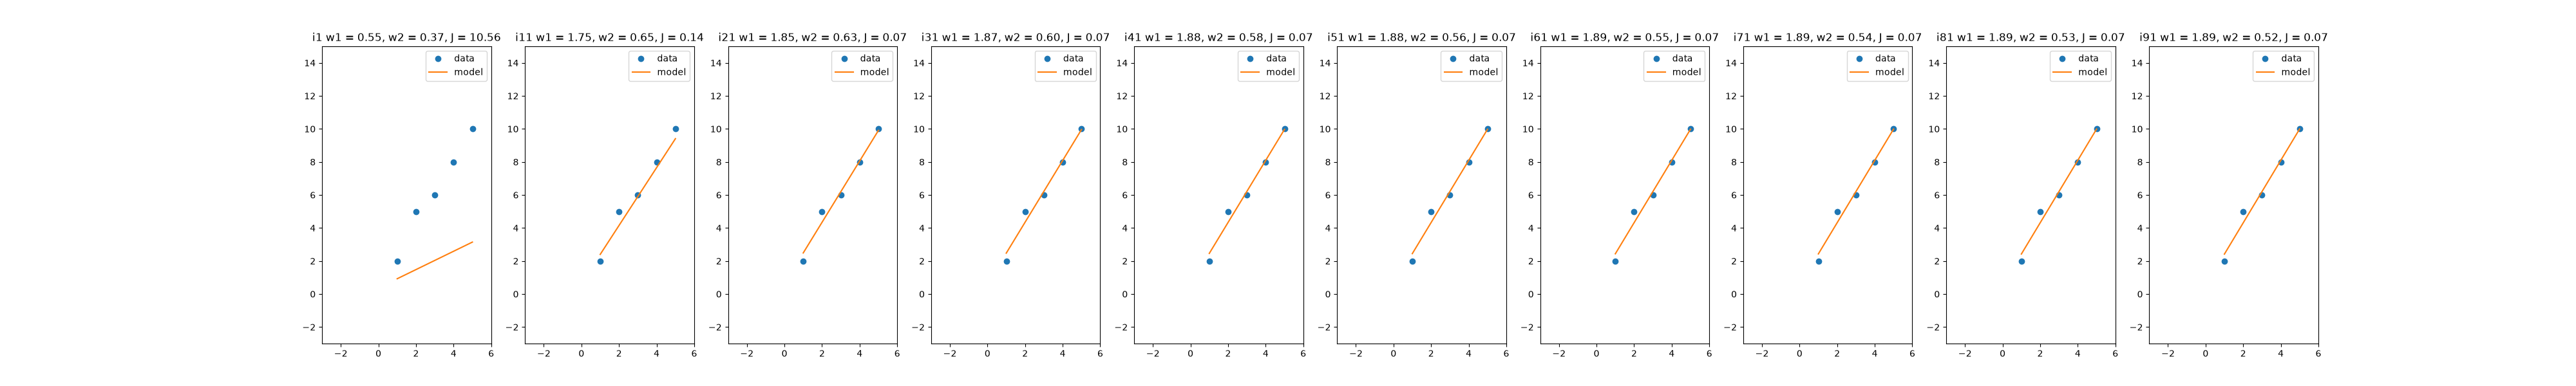

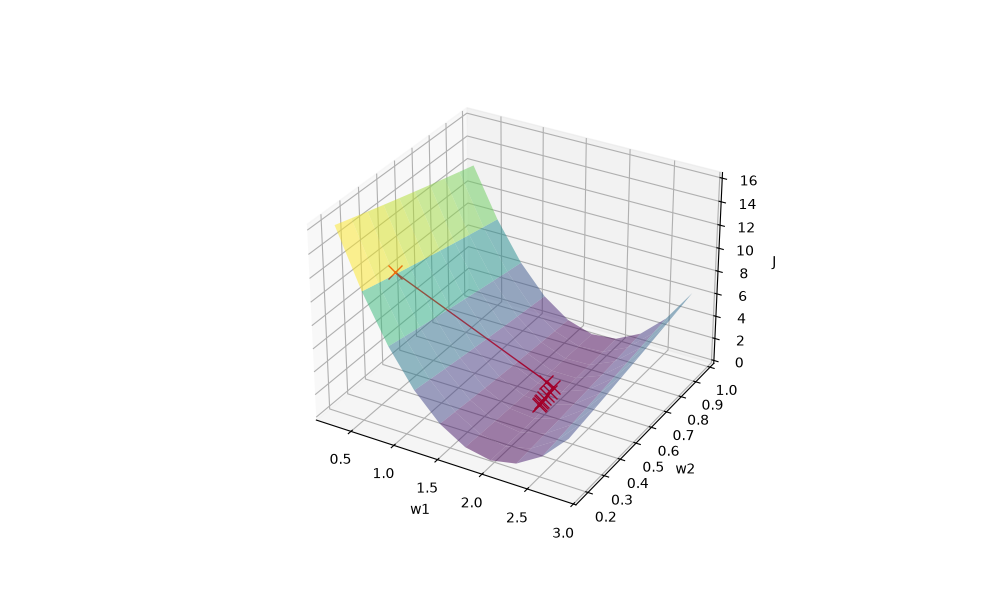

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CaratValues = np.array([1, 2, 3, 4, 5])
price_values = np.array([2, 5, 6, 8, 10])
 
def h(X, w1, w2):
    return w1 * X + w2
 
def J(X, y, w1, w2):
    n = len(y)
    return np.sum((h(X, w1, w2) - y) ** 2) / (2 * n)
 
def find_w1_w2(X, y, alpha, max_iter=10):
    w1, w2 = np.random.randn(2)
    n = len(y)
    history = []
    fig, ax = plt.subplots(1, 10, figsize=(40, 6))
    for i in range(max_iter):
        if i % 10 == 0:
            history.append((w1, w2, J(X, y, w1, w2)))
            ax[i // 10].plot(X, y, marker='o', ls='', lw=4, label='data')
            ax[i // 10].plot(X, h(X, w1, w2), label='model')
            ax[i // 10].set_title(f"i{i+1} w1 = {w1:.2f}, w2 = {w2:.2f}, J = {J(X, y, w1, w2):.2f}")
            ax[i // 10].set_xlim(-3, 6)
            ax[i // 10].set_ylim(-3, 15)
            ax[i // 10].legend()
            print(f"iteration {i+1}: w1 = {w1}, w2 = {w2}, J = {J(X, y, w1, w2)}")
        w1_tmp = w1 - alpha * np.sum((h(X, w1, w2) - y) * X) / n
        w2_tmp = w2 - alpha * np.sum((h(X, w1, w2) - y)) / n
        w1, w2 = w1_tmp, w2_tmp
    plt.savefig('gradient_descent.png')
    plt.show()
    return w1, w2, history
 
w1, w2, history = find_w1_w2(CaratValues, price_values, alpha=0.15, max_iter=100)
df = pd.DataFrame(data=history, columns=['w1', 'w2', 'J'])
min_w1, max_w1, min_w2, max_w2 = df['w1'].min(), df['w1'].max(), df['w2'].min(), df['w2'].max()
w1_range = np.linspace(min_w1-min_w1*0.5, max_w1 + max_w1*0.5, 10)
w2_range = np.linspace(min_w2-min_w2*0.5, max_w2 + max_w2*0.5, 10)
ww1, ww2 = np.meshgrid(w1_range, w2_range)
J_vals = np.zeros((len(w1_range), len(w2_range)))
for i in range(len(w1_range)):
    for j in range(len(w2_range)):
        J_vals[i, j] = J(CaratValues, price_values, ww1[i, j], ww2[i, j])
 
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='3d')
ax.plot(df['w1'], df['w2'], df['J'], marker='x', ls='-', color='red', markersize=10, lw=1, label='data')
ax.set_xlabel('w1')
ax.set_ylabel('w2')
ax.set_zlabel('J')
ax.plot_surface(ww1, ww2, J_vals, cmap='viridis', alpha=0.5)

In [36]:
# test our implementation on diamonds dataset with one parameter carat and compare  the performance to Linear regression from sklearn.

from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl

df = pd.read_csv('diamonds.csv')

In [42]:
# data cleaning

to_drop = df[(df['carat']==0)|(df['price']==0)].index
df.drop(to_drop, inplace=True)

carat_values = df['carat'].values
price_values = df['price'].values

KeyError: 'carat'

In [ ]:
# model training

model = LinearRegression()
model.fit(carat_values.reshape(-1, 1), price_values)

# print the model parameters
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: -2256.3605800453365
Coefficient: 7756.425617968352


iteration 1: w1 = 1.337668467495133, w2 = -0.4475040707579365, J = 15686355.358396102
iteration 11: w1 = 3252.4271341792637, w2 = 1633.528542996471, J = 3521731.362271386
iteration 21: w1 = 4148.366403216773, w2 = 1040.0533081162027, J = 2748557.5287469607
iteration 31: w1 = 4796.734158111795, w2 = 456.82471591179205, J = 2244848.022851619
iteration 41: w1 = 5325.07613577341, w2 = -27.060700372360316, J = 1904905.1962271745
iteration 51: w1 = 5758.928555676033, w2 = -424.83684698920365, J = 1675455.2096935688
iteration 61: w1 = 6115.35532515371, w2 = -751.6467806501653, J = 1520584.1050940712
iteration 71: w1 = 6408.182056114351, w2 = -1020.142490633503, J = 1416051.2635673136
iteration 81: w1 = 6648.757808450064, w2 = -1240.7288161999138, J = 1345495.0743673758
iteration 91: w1 = 6846.406084143659, w2 = -1421.9545094910302, J = 1297871.994752314


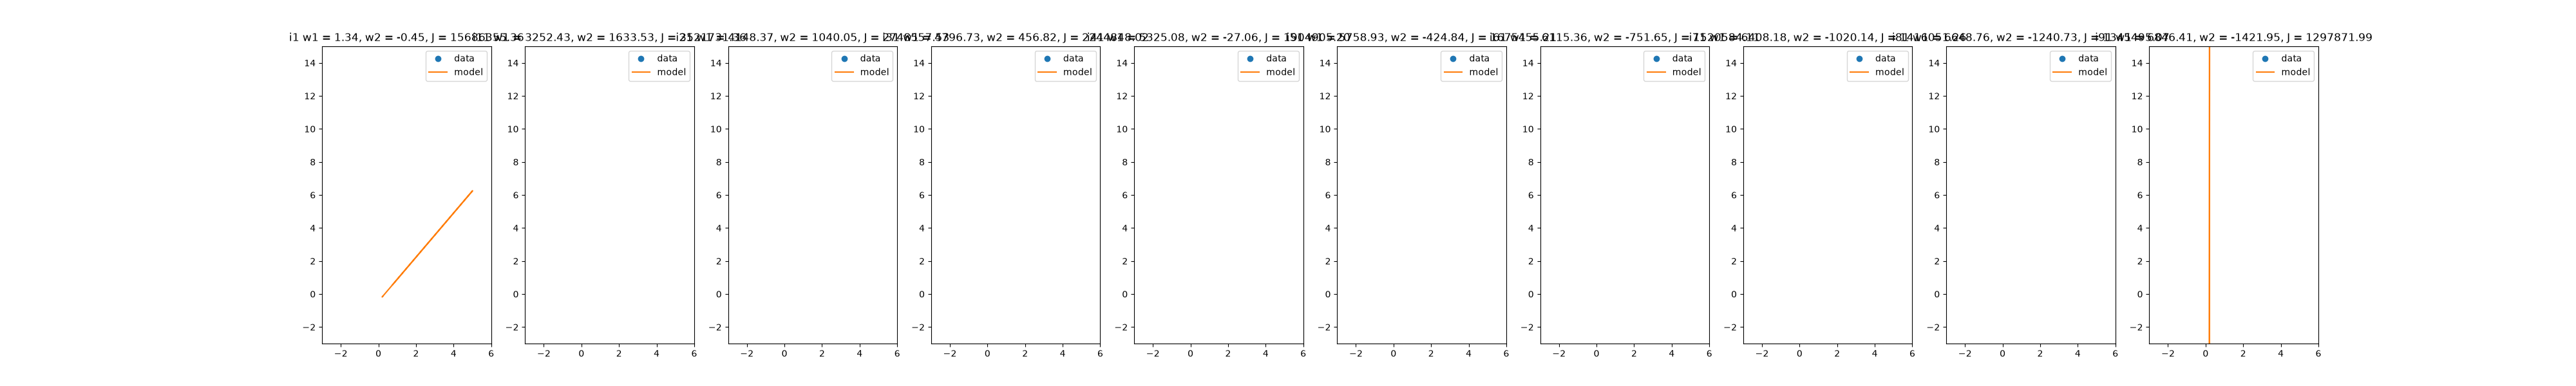

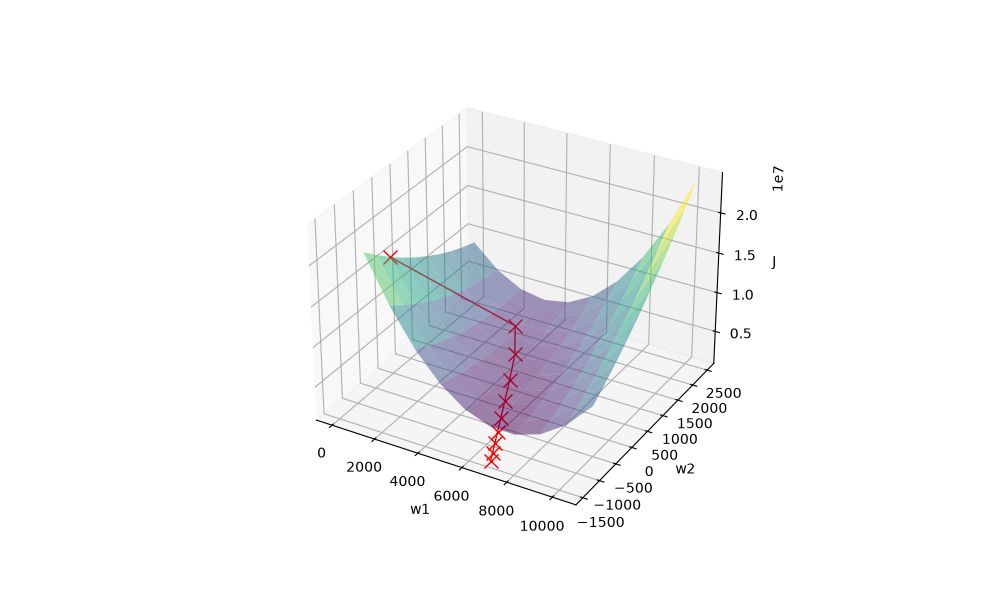

In [ ]:
def h(X, w1, w2):
    return w1 * X + w2
 
def J(X, y, w1, w2):
    n = len(y)
    return np.sum((h(X, w1, w2) - y) ** 2) / (2 * n)
 
def find_w1_w2(X, y, alpha, max_iter=10):
    w1, w2 = np.random.randn(2)
    n = len(y)
    history = []
    fig, ax = plt.subplots(1, 10, figsize=(40, 6))
    for i in range(max_iter):
        if i % 10 == 0:
            history.append((w1, w2, J(X, y, w1, w2)))
            ax[i // 10].plot(X, y, marker='o', ls='', lw=4, label='data')
            ax[i // 10].plot(X, h(X, w1, w2), label='model')
            ax[i // 10].set_title(f"i{i+1} w1 = {w1:.2f}, w2 = {w2:.2f}, J = {J(X, y, w1, w2):.2f}")
            ax[i // 10].set_xlim(-3, 6)
            ax[i // 10].set_ylim(-3, 15)
            ax[i // 10].legend()
            print(f"iteration {i+1}: w1 = {w1}, w2 = {w2}, J = {J(X, y, w1, w2)}")
        w1_tmp = w1 - alpha * np.sum((h(X, w1, w2) - y) * X) / n
        w2_tmp = w2 - alpha * np.sum((h(X, w1, w2) - y)) / n
        w1, w2 = w1_tmp, w2_tmp
    plt.savefig('gradient_descent.png')
    plt.show()
    return w1, w2, history
 
w1, w2, history = find_w1_w2(carat_values, price_values, alpha=0.15, max_iter=100)
df = pd.DataFrame(data=history, columns=['w1', 'w2', 'J'])
min_w1, max_w1, min_w2, max_w2 = df['w1'].min(), df['w1'].max(), df['w2'].min(), df['w2'].max()
w1_range = np.linspace(min_w1-min_w1*0.5, max_w1 + max_w1*0.5, 10)
w2_range = np.linspace(min_w2-min_w2*0.5, max_w2 + max_w2*0.5, 10)
ww1, ww2 = np.meshgrid(w1_range, w2_range)
J_vals = np.zeros((len(w1_range), len(w2_range)))
for i in range(len(w1_range)):
    for j in range(len(w2_range)):
        J_vals[i, j] = J(carat_values, price_values, ww1[i, j], ww2[i, j])
 
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='3d')
ax.plot(df['w1'], df['w2'], df['J'], marker='x', ls='-', color='red', markersize=10, lw=1, label='data')
ax.set_xlabel('w1')
ax.set_ylabel('w2')
ax.set_zlabel('J')
ax.plot_surface(ww1, ww2, J_vals, cmap='viridis', alpha=0.5)